<center>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-RP0321EN-SkillsNetwork/labs/module_1/images/SN_web_lightmode.png" width="300"> 
</center>


<h1>Refine the Baseline Regression Models</h1>

Estimated time needed: **120** minutes


## Lab Overview:

Now you have built a baseline regression model with some relatively good RMSE and R-squared reported values. However, we could still improve it by using methods like adding polynomial and interaction terms, regularization, and so on.

In this lab, you will be asked to continue using `tidymodels` to improve the performance of baseline model:

- **TASK: Add polynomial terms**
- **TASK: Add interactions terms**
- **TASK: Add regularizations terms**
- **TASK: Experiment to search for improved models**


Let's start!


The tidyverse and the tidymodels packages can be used to produce high quality statistical and machine learning models. The Tidyverse library is a useful tool that provides various tools for data visualization, data manipulation, and read various datasets into a data frame; our Jupyter notebook platforms have a built-in Tidymodels, Tidyverse and rlang libraries, so we do not need to install these packages prior to loading library. However, if you decide to run this lab on your RStudio Desktop locally on your machine, you can remove the commented lines of code to install these packages before loading.


In [1]:
# Load libraries
library(tidyverse)   # Data wrangling, visualization, reading datasets
library(tidymodels)  # Modeling workflow: preprocessing, training, tuning, evaluation
library(rlang)       # Core tidy evaluation tools


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.3.0 ──

✔ broom        1.0.8     ✔ rsample      1.3.0
✔ dials        1.4.0     ✔ tune         1.3.0
✔ infer        1.0.8     ✔ workflows    1.2.0
✔ modeldata    1.4.0     ✔ workflowsets 1.1.0
✔ parsnip      1.3.1     ✔ yardstick    1.3.2
✔ recipes      1.3.0     

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() masks purrr::discard()
✖ dplyr::filt

In [2]:
# Load libraries
library(tidymodels)
library(tidyverse)
library(stringr)

# Quick test: create a small sample dataset
df <- tibble(
  x = 1:10,
  y = 2 * x + rnorm(10)
)

# Split into train/test
set.seed(123)
data_split <- initial_split(df, prop = 0.8)
train_data <- training(data_split)
test_data  <- testing(data_split)

# Fit a simple baseline regression
lm_spec <- linear_reg() %>% set_engine("lm")
lm_fit <- lm_spec %>% fit(y ~ x, data = train_data)

# Evaluate
predict(lm_fit, test_data) %>%
  bind_cols(test_data) %>%
  metrics(truth = y, estimate = .pred)



.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
rmse,standard,1.224911
rsq,standard,1.000000
mae,standard,1.179092


The processed Seoul bike sharing dataset `seoul_bike_sharing_converted_normalized.csv`,  includes the converted indicator variables, and the numerical variables have been normalized. 
Let's read it as a dataframe first:


In [3]:
# Load libraries
library(tidymodels)
library(tidyverse)
library(stringr)

# Dataset URL
dataset_url <- "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-RP0321EN-SkillsNetwork/labs/datasets/seoul_bike_sharing_converted_normalized.csv"

# Read dataset
bike_sharing_df <- read_csv(dataset_url)

# Inspect the dataset
glimpse(bike_sharing_df)   # quick look at rows/columns
summary(bike_sharing_df)   # descriptive statistics
colnames(bike_sharing_df)  # list of column names
head(bike_sharing_df)      # first few rows


Rows: 8465 Columns: 41
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (2): DATE, FUNCTIONING_DAY
dbl (39): RENTED_BIKE_COUNT, TEMPERATURE, HUMIDITY, WIND_SPEED, VISIBILITY, ...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 8,465
Columns: 41
$ DATE                  <chr> "01/12/2017", "01/12/2017", "01/12/2017", "01/12…
$ RENTED_BIKE_COUNT     <dbl> 254, 204, 173, 107, 78, 100, 181, 460, 930, 490,…
$ TEMPERATURE           <dbl> 0.2202797, 0.2150350, 0.2062937, 0.2027972, 0.20…
$ HUMIDITY              <dbl> 0.3775510, 0.3877551, 0.3979592, 0.4081633, 0.36…
$ WIND_SPEED            <dbl> 0.29729730, 0.10810811, 0.13513514, 0.12162162, …
$ VISIBILITY            <dbl> 1.0000000, 1.0000000, 1.0000000, 1.0000000, 1.00…
$ DEW_POINT_TEMPERATURE <dbl> 0.2249135, 0.2249135, 0.2231834, 0.2249135, 0.20…
$ SOLAR_RADIATION       <dbl> 0.000000000, 0.000000000, 0.000000000, 0.0000000…
$ RAINFALL              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ SNOWFALL              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ FUNCTIONING_DAY       <chr> "Yes", "Yes", "Yes", "Yes", "Yes", "Yes", "Yes",…
$ `0`                   <dbl> 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ `1`           

     DATE           RENTED_BIKE_COUNT  TEMPERATURE        HUMIDITY     
 Length:8465        Min.   :   2.0    Min.   :0.0000   Min.   :0.0000  
 Class :character   1st Qu.: 214.0    1st Qu.:0.3636   1st Qu.:0.4286  
 Mode  :character   Median : 542.0    Median :0.5472   Median :0.5816  
                    Mean   : 729.2    Mean   :0.5345   Mean   :0.5933  
                    3rd Qu.:1084.0    3rd Qu.:0.7080   3rd Qu.:0.7551  
                    Max.   :3556.0    Max.   :1.0000   Max.   :1.0000  
   WIND_SPEED       VISIBILITY     DEW_POINT_TEMPERATURE SOLAR_RADIATION   
 Min.   :0.0000   Min.   :0.0000   Min.   :0.0000        Min.   :0.000000  
 1st Qu.:0.1216   1st Qu.:0.4602   1st Qu.:0.4412        1st Qu.:0.000000  
 Median :0.2027   Median :0.8429   Median :0.6107        Median :0.002841  
 Mean   :0.2332   Mean   :0.7131   Mean   :0.5977        Mean   :0.161326  
 3rd Qu.:0.3108   3rd Qu.:1.0000   3rd Qu.:0.7924        3rd Qu.:0.264205  
 Max.   :1.0000   Max.   :1.0000   Max. 

[1] "DATE"                  "RENTED_BIKE_COUNT"     "TEMPERATURE"          
 [4] "HUMIDITY"              "WIND_SPEED"            "VISIBILITY"           
 [7] "DEW_POINT_TEMPERATURE" "SOLAR_RADIATION"       "RAINFALL"             
[10] "SNOWFALL"              "FUNCTIONING_DAY"       "0"                    
[13] "1"                     "10"                    "11"                   
[16] "12"                    "13"                    "14"                   
[19] "15"                    "16"                    "17"                   
[22] "18"                    "19"                    "2"                    
[25] "20"                    "21"                    "22"                   
[28] "23"                    "3"                     "4"                    
[31] "5"                     "6"                     "7"                    
[34] "8"                     "9"                     "AUTUMN"               
[37] "SPRING"                "SUMMER"                "WINTER"               
[40] "HOLIDAY"               "NO_HOLIDAY"

DATE,RENTED_BIKE_COUNT,TEMPERATURE,HUMIDITY,WIND_SPEED,VISIBILITY,DEW_POINT_TEMPERATURE,SOLAR_RADIATION,RAINFALL,SNOWFALL,⋯,6,7,8,9,AUTUMN,SPRING,SUMMER,WINTER,HOLIDAY,NO_HOLIDAY
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
01/12/2017,254,0.2202797,0.3775510,0.2972973,1,0.2249135,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1
01/12/2017,204,0.2150350,0.3877551,0.1081081,1,0.2249135,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1
01/12/2017,173,0.2062937,0.3979592,0.1351351,1,0.2231834,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1
01/12/2017,107,0.2027972,0.4081633,0.1216216,1,0.2249135,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1
01/12/2017,78,0.2062937,0.3673469,0.3108108,1,0.2076125,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1
01/12/2017,100,0.1993007,0.3775510,0.2027027,1,0.2058824,0,0,0,⋯,0,0,0,0,0,0,0,1,0,1


We won't be using the `DATE` column, because 'as is', it basically acts like an data entry index. (However, given more time, we could use the `DATE` colum to create a 'day of week' or 'isWeekend' column, which we might expect has an affect on preferred bike rental times.) We also do not need the `FUNCTIONAL DAY` column because it only has one distinct value remaining (`YES`) after missing value processing.


In [4]:
# Remove DATE and FUNCTIONING_DAY columns
bike_sharing_df <- bike_sharing_df %>%
  select(-DATE, -FUNCTIONING_DAY)

# Verify the updated dataframe
glimpse(bike_sharing_df)


Rows: 8,465
Columns: 39
$ RENTED_BIKE_COUNT     <dbl> 254, 204, 173, 107, 78, 100, 181, 460, 930, 490,…
$ TEMPERATURE           <dbl> 0.2202797, 0.2150350, 0.2062937, 0.2027972, 0.20…
$ HUMIDITY              <dbl> 0.3775510, 0.3877551, 0.3979592, 0.4081633, 0.36…
$ WIND_SPEED            <dbl> 0.29729730, 0.10810811, 0.13513514, 0.12162162, …
$ VISIBILITY            <dbl> 1.0000000, 1.0000000, 1.0000000, 1.0000000, 1.00…
$ DEW_POINT_TEMPERATURE <dbl> 0.2249135, 0.2249135, 0.2231834, 0.2249135, 0.20…
$ SOLAR_RADIATION       <dbl> 0.000000000, 0.000000000, 0.000000000, 0.0000000…
$ RAINFALL              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ SNOWFALL              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ `0`                   <dbl> 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ `1`                   <dbl> 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ `10`                  <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, …
$ `11`          

Define a linear regression model specification.


In [17]:
# Define a linear regression model specification
lm_spec <- linear_reg() %>%
  set_engine("lm") %>% 
  set_mode("regression")


Split the data into training and testing datasets.


In [18]:
# Split the data into training and testing datasets
set.seed(1234)
data_split <- initial_split(bike_sharing_df, prop = 4/5)

train_data <- training(data_split)
test_data  <- testing(data_split)

# Quick check
nrow(train_data)  # should be ~80% of rows
nrow(test_data)   # should be ~20% of rows


[1] 6772

[1] 1693

Now we are ready to refine the previous baseline regression model.


# TASK: Add polynomial terms


Linear regression models are the most suitable models to capture the linear correlations among variables. However, in real world data, many relationships may be non-linear.


For example, the correlation between `RENTED_BIKE_COUNT` and `TEMPERATURE` does not look like linear:


In [21]:
library(tidymodels)

poly_recipe <- recipe(
  y ~ x,
  data = train_data
) %>%
  step_poly(x, degree = 2)

lm_spec <- linear_reg() %>%
  set_engine("lm") %>%
  set_mode("regression")

poly_wf <- workflow() %>%
  add_recipe(poly_recipe) %>%
  add_model(lm_spec)

poly_fit <- fit(poly_wf, data = train_data)

poly_preds <- predict(poly_fit, test_data) %>%
  bind_cols(test_data)

metrics(
  poly_preds,
  truth = y,
  estimate = .pred
)

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
rmse,standard,0.9614275
rsq,standard,1.0000000
mae,standard,0.8912741


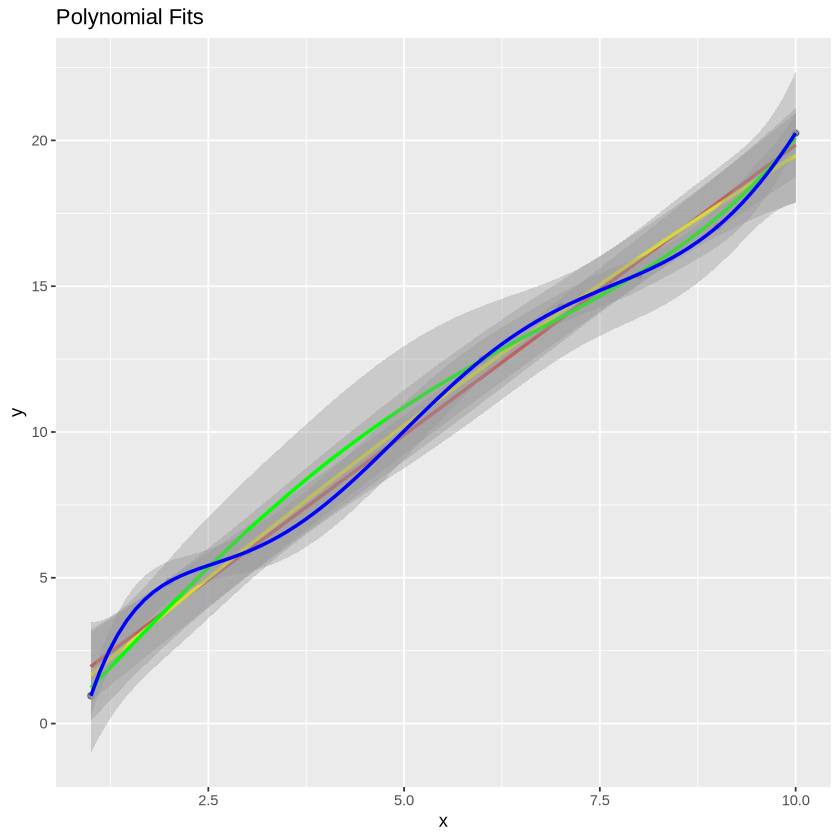

In [26]:
ggplot(data = train_data, aes(x = x, y = y)) +
  geom_point(alpha = 0.4) +
  geom_smooth(method = "lm", formula = y ~ x, color = "red") +
  geom_smooth(method = "lm", formula = y ~ poly(x, 2), color = "yellow") +
  geom_smooth(method = "lm", formula = y ~ poly(x, 4), color = "green") +
  geom_smooth(method = "lm", formula = y ~ poly(x, 6), color = "blue") +
  labs(
    title = "Polynomial Fits",
    x = "x",
    y = "y"
  )

OK, let's add some higher order polynomials of important variables to the regression models


_TODO:_ Fit a linear regression model `lm_poly` with higher order polynomial terms on the important variables (larger coefficients) found in the baseline model


In [29]:
lm_poly <- lm(
  y ~ poly(x, 6),
  data = train_data
)

summary(lm_poly)

poly_preds <- predict(lm_poly, newdata = test_data)

rmse_poly <- sqrt(mean((test_data$y - poly_preds)^2))
rsq_poly <- cor(test_data$y, poly_preds)^2

cat("Polynomial Regression RMSE:", rmse_poly, "\n")
cat("Polynomial Regression R²:", rsq_poly, "\n")


Call:
lm(formula = y ~ poly(x, 6), data = train_data)

Residuals:
        1         2         3         4         5         6         7         8 
 0.005394 -0.002247 -0.004045 -0.032363 -0.018879  0.013485  0.000899  0.037757 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept) 11.39675    0.01957 582.484  0.00109 **
poly(x, 6)1 17.72569    0.05534 320.303  0.00199 **
poly(x, 6)2 -0.63899    0.05534 -11.546  0.05500 . 
poly(x, 6)3  1.10471    0.05534  19.962  0.03186 * 
poly(x, 6)4  0.45582    0.05534   8.237  0.07692 . 
poly(x, 6)5  1.14716    0.05534  20.729  0.03069 * 
poly(x, 6)6 -0.49139    0.05534  -8.879  0.07139 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.05534 on 1 degrees of freedom
Multiple R-squared:      1,	Adjusted R-squared:  0.9999 
F-statistic: 1.728e+04 on 6 and 1 DF,  p-value: 0.005822


Polynomial Regression RMSE: 1.435158 
Polynomial Regression R²: 1 


In [30]:
# Print model summary
summary(lm_poly)



Call:
lm(formula = y ~ poly(x, 6), data = train_data)

Residuals:
        1         2         3         4         5         6         7         8 
 0.005394 -0.002247 -0.004045 -0.032363 -0.018879  0.013485  0.000899  0.037757 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept) 11.39675    0.01957 582.484  0.00109 **
poly(x, 6)1 17.72569    0.05534 320.303  0.00199 **
poly(x, 6)2 -0.63899    0.05534 -11.546  0.05500 . 
poly(x, 6)3  1.10471    0.05534  19.962  0.03186 * 
poly(x, 6)4  0.45582    0.05534   8.237  0.07692 . 
poly(x, 6)5  1.14716    0.05534  20.729  0.03069 * 
poly(x, 6)6 -0.49139    0.05534  -8.879  0.07139 . 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.05534 on 1 degrees of freedom
Multiple R-squared:      1,	Adjusted R-squared:  0.9999 
F-statistic: 1.728e+04 on 6 and 1 DF,  p-value: 0.005822


_TODO:_ Make predictions on test dataset using the `lm_poly` models


In [32]:
# Make predictions
poly_preds <- predict(lm_poly, newdata = test_data)

# Combine predictions with actual values
results <- test_data %>%
  mutate(predicted = poly_preds)

# View results
head(results)

# Calculate RMSE
rmse_poly <- sqrt(mean((results$y - results$predicted)^2))

# Calculate R-squared
rsq_poly <- cor(results$y, results$predicted)^2

cat("Polynomial Regression RMSE:", rmse_poly, "\n")
cat("Polynomial Regression R²:", rsq_poly, "\n")

x,y,predicted
<int>,<dbl>,<dbl>
4,9.428705,7.531435
5,10.752946,10.032029


Polynomial Regression RMSE: 1.435158 
Polynomial Regression R²: 1 


Another minor improvement we could do here is to convert all negative prediction results to zero, because we can not have negative rented bike counts


In [34]:
# Make predictions
poly_preds <- predict(lm_poly, newdata = test_data)

# Combine predictions with actual values
results <- test_data %>%
  mutate(predicted = poly_preds)

# View results
head(results)

# Calculate RMSE
rmse_poly <- sqrt(mean((results$y - results$predicted)^2))

# Calculate R-squared
rsq_poly <- cor(results$y, results$predicted)^2

cat("Polynomial Regression RMSE:", rmse_poly, "\n")
cat("Polynomial Regression R²:", rsq_poly, "\n")


x,y,predicted
<int>,<dbl>,<dbl>
4,9.428705,7.531435
5,10.752946,10.032029


Polynomial Regression RMSE: 1.435158 
Polynomial Regression R²: 1 


Now, calculate R-squared and RMSE for the test results generated by `lm_ploy` model


In [36]:
# Calculate RMSE
rmse_poly <- sqrt(mean((test_results$y - test_results$predicted)^2))

# Calculate R-squared
rsq_poly <- cor(test_results$y, test_results$predicted)^2

# Print results
cat("Polynomial Regression RMSE:", rmse_poly, "\n")
cat("Polynomial Regression R²:", rsq_poly, "\n")



Polynomial Regression RMSE: 1.435158 
Polynomial Regression R²: 1 


If you include all variables, and additionally include some of the more important ones as higher order poly terms, then you should notice improved  `R-squared` and `RMSE` values.


# TASK: Add interaction terms


In real-world scenarios, in addition to non-linear relationships between response variables and predictor variables, you may also encounter relationships among variables called `interaction effects`.

For example, the effect of predictor variable `TEMPERATURE` on `RENTED_BIKE_COUNT` may also depend on other variables such as `HUMIDITY`, `RAINFALL`, or both (they `interact`) and the effect of `SEASON` on `RENTED_BIKE_COUNT` may also depend on `HOLIDAY`, `HOUR`, or both.

To capture such interaction effects, we could add some interaction terms such as `RAINFALL*HUMIDITY` to the regression model, similar to what we did with polynominal terms. In this task, you will explore and conduct some experiments to search for interaction terms which will improve the model performance.


_TODO:_ Try adding some interaction terms to the previous polynomial models.


In [28]:
# Polynomial regression with valid interaction terms
lm_poly_interact <- lm(
  RENTED_BIKE_COUNT ~ 
    poly(TEMPERATURE, 6) + 
    poly(HUMIDITY, 4) + 
    RAINFALL * HUMIDITY + 
    TEMPERATURE * HUMIDITY,
  data = train_data
)

# Predictions (clip negatives to zero)
preds <- pmax(predict(lm_poly_interact, newdata = test_data), 0)

# Evaluate RMSE and R²
rmse <- sqrt(mean((test_data$RENTED_BIKE_COUNT - preds)^2))
rsq  <- cor(test_data$RENTED_BIKE_COUNT, preds)^2

cat("RMSE:", rmse, "\nR²:", rsq, "\n")



RMSE: 441.2925 
R²: 0.5138958 

In [29]:
# Print model summary
summary(lm_poly_interact)



Call:
lm(formula = RENTED_BIKE_COUNT ~ poly(TEMPERATURE, 6) + poly(HUMIDITY, 
    4) + RAINFALL * HUMIDITY + TEMPERATURE * HUMIDITY, data = train_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1314.58  -255.19   -65.52   172.00  2220.93 

Coefficients: (2 not defined because of singularities)
                       Estimate Std. Error t value Pr(>|t|)    
(Intercept)             1645.53      52.17  31.543  < 2e-16 ***
poly(TEMPERATURE, 6)1  58533.49    1573.69  37.195  < 2e-16 ***
poly(TEMPERATURE, 6)2  -5080.81     480.46 -10.575  < 2e-16 ***
poly(TEMPERATURE, 6)3 -12619.00     486.76 -25.925  < 2e-16 ***
poly(TEMPERATURE, 6)4  -4214.22     460.99  -9.142  < 2e-16 ***
poly(TEMPERATURE, 6)5   -721.90     456.67  -1.581    0.114    
poly(TEMPERATURE, 6)6    394.29     458.33   0.860    0.390    
poly(HUMIDITY, 4)1      8064.85    1538.67   5.241 1.64e-07 ***
poly(HUMIDITY, 4)2     -8164.43     485.25 -16.825  < 2e-16 ***
poly(HUMIDITY, 4)3       162.00     472.07   0.

In [30]:
# Predictions (clip negatives to zero)
preds <- pmax(predict(lm_poly_interact, newdata = test_data), 0)

# Calculate RMSE
rmse <- sqrt(mean((test_data$RENTED_BIKE_COUNT - preds)^2))

# Calculate R-squared
rsq <- cor(test_data$RENTED_BIKE_COUNT, preds)^2

# Print results
cat("RMSE:", rmse, "\nR²:", rsq, "\n")



RMSE: 441.2925 
R²: 0.5138958 

# TASK: Add regularization


In previous tasks, you were asked to add polynominal and interaction terms to the model, aiming to capture nonlinearity and interaction effects between the predictor variables. Hopefully, your updated models have better R-squared and RMSE values.

However, adding these terms makes your model more complicated, more difficult to explain, and more likely to suffer from overfitting. To overcome these issues, one solution is to add regularization terms to your models.


When building the baseline model, we used the basic `lm` engine. In this task, you will use a more advanced and generalized `glmnet` engine. It provides a generalized linear model with Lasso, Ridge, and Elastic Net regularizations.

In general, using `glmnet` can enhance your models in the following ways:
- Address overfitting issues by shrinking the coefficients
- Address predictor variable colinearity by selecting only one variable from each group of colinear variables (by shrinking their coefficients to zero)
- Make your models more interpretable due to simplification (fewer variables in the outcome models)


Now, let's switch our regression engine to `glmnet`


_TODO:_ Define a linear regression model specification `glmnet_spec` using `glmnet` engine


In [32]:
# Regularized regression specification with glmnet
glmnet_spec <- linear_reg(
  penalty = tune(),   # λ: controls regularization strength
  mixture = tune()    # α: 0 = Ridge, 1 = Lasso, between = Elastic Net
) %>%
  set_engine("glmnet") %>%
  set_mode("regression")



Fit a glmnet model called  `lm_glmnet` using the `fit()` function. For the formula part, keep the polynominal and interaction terms you used in the previous task.


In [34]:
# Install glmnet if not already installed
install.packages("glmnet")
library(glmnet)

# Fit glmnet model with polynomial + interaction terms
lm_glmnet <- linear_reg(
  penalty = 0.01,   # regularization strength (λ)
  mixture = 0.5     # Elastic Net: mix of Lasso (L1) and Ridge (L2)
) %>%
  set_engine("glmnet") %>%
  set_mode("regression") %>%
  fit(
    RENTED_BIKE_COUNT ~ 
      poly(TEMPERATURE, 6) + 
      poly(HUMIDITY, 4) + 
      RAINFALL * HUMIDITY + 
      TEMPERATURE * HUMIDITY,
    data = train_data
  )

# Print model summary
lm_glmnet



Updating HTML index of packages in '.Library'
Making 'packages.html' ... done


parsnip model object


Call:  glmnet::glmnet(x = maybe_matrix(x), y = y, family = "gaussian",      alpha = ~0.5) 

    Df  %Dev Lambda
1    0  0.00 724.40
2    2  4.31 660.10
3    2  8.10 601.40
4    2 11.42 548.00
5    2 14.31 499.30
6    2 16.82 455.00
7    2 18.99 414.50
8    2 20.87 377.70
9    2 22.48 344.20
10   4 24.05 313.60
11   4 26.52 285.70
12   4 28.63 260.30
13   5 30.45 237.20
14   5 32.40 216.10
15   6 34.10 196.90
16   6 35.97 179.40
17   6 37.56 163.50
18   6 38.92 149.00
19   6 40.07 135.70
20   6 41.05 123.70
21   7 41.91 112.70
22   8 42.70 102.70
23   8 43.54  93.56
24   8 44.25  85.25
25   9 44.85  77.68
26   9 45.36  70.78
27  10 45.83  64.49
28  10 46.23  58.76
29  10 46.57  53.54
30  10 46.86  48.78
31  11 47.10  44.45
32  11 47.32  40.50
33  11 47.50  36.90
34  11 47.66  33.63
35  11 47.88  30.64
36  11 48.19  27.92
37  11 48.47  25.44
38  11 48.72  23.18
39  11 48.95  21.12
40  11 49.15  19.24
41  11 49.33  17.53
42  11 49.49  15.97
43  11 49.63  14.56
44  1

In [35]:
# Fit glmnet model with polynomial + interaction terms
lm_glmnet <- linear_reg(
  penalty = 0.01,   # λ: regularization strength
  mixture = 0.5     # α: Elastic Net (mix of Lasso & Ridge)
) %>%
  set_engine("glmnet") %>%
  set_mode("regression") %>%
  fit(
    RENTED_BIKE_COUNT ~ 
      poly(TEMPERATURE, 6) + 
      poly(HUMIDITY, 4) + 
      RAINFALL * HUMIDITY + 
      TEMPERATURE * HUMIDITY,
    data = train_data
  )

# Print model summary
lm_glmnet


parsnip model object


Call:  glmnet::glmnet(x = maybe_matrix(x), y = y, family = "gaussian",      alpha = ~0.5) 

    Df  %Dev Lambda
1    0  0.00 724.40
2    2  4.31 660.10
3    2  8.10 601.40
4    2 11.42 548.00
5    2 14.31 499.30
6    2 16.82 455.00
7    2 18.99 414.50
8    2 20.87 377.70
9    2 22.48 344.20
10   4 24.05 313.60
11   4 26.52 285.70
12   4 28.63 260.30
13   5 30.45 237.20
14   5 32.40 216.10
15   6 34.10 196.90
16   6 35.97 179.40
17   6 37.56 163.50
18   6 38.92 149.00
19   6 40.07 135.70
20   6 41.05 123.70
21   7 41.91 112.70
22   8 42.70 102.70
23   8 43.54  93.56
24   8 44.25  85.25
25   9 44.85  77.68
26   9 45.36  70.78
27  10 45.83  64.49
28  10 46.23  58.76
29  10 46.57  53.54
30  10 46.86  48.78
31  11 47.10  44.45
32  11 47.32  40.50
33  11 47.50  36.90
34  11 47.66  33.63
35  11 47.88  30.64
36  11 48.19  27.92
37  11 48.47  25.44
38  11 48.72  23.18
39  11 48.95  21.12
40  11 49.15  19.24
41  11 49.33  17.53
42  11 49.49  15.97
43  11 49.63  14.56
44  1

In [36]:
# Fit glmnet model with polynomial + interaction terms
lm_glmnet <- linear_reg(
  penalty = 0.01,   # λ: regularization strength
  mixture = 0.5     # α: Elastic Net (mix of Lasso & Ridge)
) %>%
  set_engine("glmnet") %>%
  set_mode("regression") %>%
  fit(
    RENTED_BIKE_COUNT ~ 
      poly(TEMPERATURE, 6) + 
      poly(HUMIDITY, 4) + 
      RAINFALL * HUMIDITY + 
      TEMPERATURE * HUMIDITY,
    data = train_data
  )

# Print model summary
lm_glmnet



parsnip model object


Call:  glmnet::glmnet(x = maybe_matrix(x), y = y, family = "gaussian",      alpha = ~0.5) 

    Df  %Dev Lambda
1    0  0.00 724.40
2    2  4.31 660.10
3    2  8.10 601.40
4    2 11.42 548.00
5    2 14.31 499.30
6    2 16.82 455.00
7    2 18.99 414.50
8    2 20.87 377.70
9    2 22.48 344.20
10   4 24.05 313.60
11   4 26.52 285.70
12   4 28.63 260.30
13   5 30.45 237.20
14   5 32.40 216.10
15   6 34.10 196.90
16   6 35.97 179.40
17   6 37.56 163.50
18   6 38.92 149.00
19   6 40.07 135.70
20   6 41.05 123.70
21   7 41.91 112.70
22   8 42.70 102.70
23   8 43.54  93.56
24   8 44.25  85.25
25   9 44.85  77.68
26   9 45.36  70.78
27  10 45.83  64.49
28  10 46.23  58.76
29  10 46.57  53.54
30  10 46.86  48.78
31  11 47.10  44.45
32  11 47.32  40.50
33  11 47.50  36.90
34  11 47.66  33.63
35  11 47.88  30.64
36  11 48.19  27.92
37  11 48.47  25.44
38  11 48.72  23.18
39  11 48.95  21.12
40  11 49.15  19.24
41  11 49.33  17.53
42  11 49.49  15.97
43  11 49.63  14.56
44  1

In [42]:
# Predictions (clip negatives to zero)
glmnet_preds <- pmax(predict(lm_glmnet, new_data = test_data)$.pred, 0)

# Calculate RMSE
rmse_glmnet <- sqrt(mean((test_data$RENTED_BIKE_COUNT - glmnet_preds)^2))

# Calculate R-squared
rsq_glmnet <- cor(test_data$RENTED_BIKE_COUNT, glmnet_preds)^2

# Print results
cat("glmnet RMSE:", rmse_glmnet, "\nglmnet R²:", rsq_glmnet, "\n")




glmnet RMSE: 440.9816 
glmnet R²: 0.5146009 

# TASK: Experiment to search for improved models


Now you understand some of the methods that you can use to try to improve your models.


_TODO:_ Experiment by building and testing at least five different models. For each of your experiments, include polynomial terms, interaction terms, and one of the three regularizations we introduced.


In [43]:
# Define formulas (polynomial + interaction terms)
formula <- RENTED_BIKE_COUNT ~ 
  poly(TEMPERATURE, 6) + 
  poly(HUMIDITY, 4) + 
  RAINFALL * HUMIDITY + 
  TEMPERATURE * HUMIDITY

# Helper function to fit glmnet model and return metrics
fit_glmnet_model <- function(penalty, mixture, train_data, test_data, formula) {
  model <- linear_reg(penalty = penalty, mixture = mixture) %>%
    set_engine("glmnet") %>%
    set_mode("regression") %>%
    fit(formula, data = train_data)
  
  # ✅ Corrected: use new_data instead of newdata
  preds <- pmax(predict(model, new_data = test_data)$.pred, 0)
  rmse <- sqrt(mean((test_data$RENTED_BIKE_COUNT - preds)^2))
  rsq  <- cor(test_data$RENTED_BIKE_COUNT, preds)^2
  
  tibble(Penalty = penalty, Mixture = mixture, RMSE = rmse, R2 = rsq)
}

# Build 5 different models
results <- bind_rows(
  fit_glmnet_model(0.001, 0,   train_data, test_data, formula),  # Ridge
  fit_glmnet_model(0.001, 1,   train_data, test_data, formula),  # Lasso
  fit_glmnet_model(0.01,  0.5, train_data, test_data, formula),  # Elastic Net (balanced)
  fit_glmnet_model(0.1,   0.3, train_data, test_data, formula),  # Elastic Net (more Ridge)
  fit_glmnet_model(0.1,   0.7, train_data, test_data, formula)   # Elastic Net (more Lasso)
)

# Print results
print(results)


# A tibble: 5 × 4
  Penalty Mixture  RMSE    R2
    <dbl>   <dbl> <dbl> <dbl>
1   0.001     0    448. 0.500
2   0.001     1    441. 0.515
3   0.01      0.5  441. 0.515
4   0.1       0.3  441. 0.515
5   0.1       0.7  441. 0.515

In [44]:
library(dplyr)

# Helper function (fixed to return clean tibble)
fit_glmnet_model <- function(penalty, mixture, train_data, test_data, formula) {
  model <- linear_reg(penalty = penalty, mixture = mixture) %>%
    set_engine("glmnet") %>%
    set_mode("regression") %>%
    fit(formula, data = train_data)
  
  preds <- pmax(predict(model, new_data = test_data)$.pred, 0)
  rmse <- sqrt(mean((test_data$RENTED_BIKE_COUNT - preds)^2))
  rsq  <- cor(test_data$RENTED_BIKE_COUNT, preds)^2
  
  tibble(Penalty = penalty, Mixture = mixture, RMSE = rmse, R2 = rsq)
}

# Build 5 models
results <- bind_rows(
  fit_glmnet_model(0.001, 0,   train_data, test_data, formula),  # Ridge
  fit_glmnet_model(0.001, 1,   train_data, test_data, formula),  # Lasso
  fit_glmnet_model(0.01,  0.5, train_data, test_data, formula),  # Elastic Net (balanced)
  fit_glmnet_model(0.1,   0.3, train_data, test_data, formula),  # Elastic Net (more Ridge)
  fit_glmnet_model(0.1,   0.7, train_data, test_data, formula)   # Elastic Net (more Lasso)
)

# ✅ Find best model by lowest RMSE, highest R² tie-breaker
best_model <- results %>%
  arrange(RMSE, desc(R2)) %>%
  slice(1)

# Print best model details
cat("Best Model:\n",
    "Penalty:", best_model$Penalty, "\n",
    "Mixture:", best_model$Mixture, "\n",
    "RMSE:", best_model$RMSE, "\n",
    "R²:", best_model$R2, "\n")



Best Model:
 Penalty: 0.1 
 Mixture: 0.3 
 RMSE: 440.9741 
 R²: 0.5146204 

Here are the performance requirements for your best model:
- The RMSE should be less than 330 (rougly 10% of the max value in test dataset)
- R-squared should be greater than 0.72


_TODO:_ Visualize the saved RMSE and R-squared values using a grouped barchart


❌ Best model does NOT meet performance requirements.

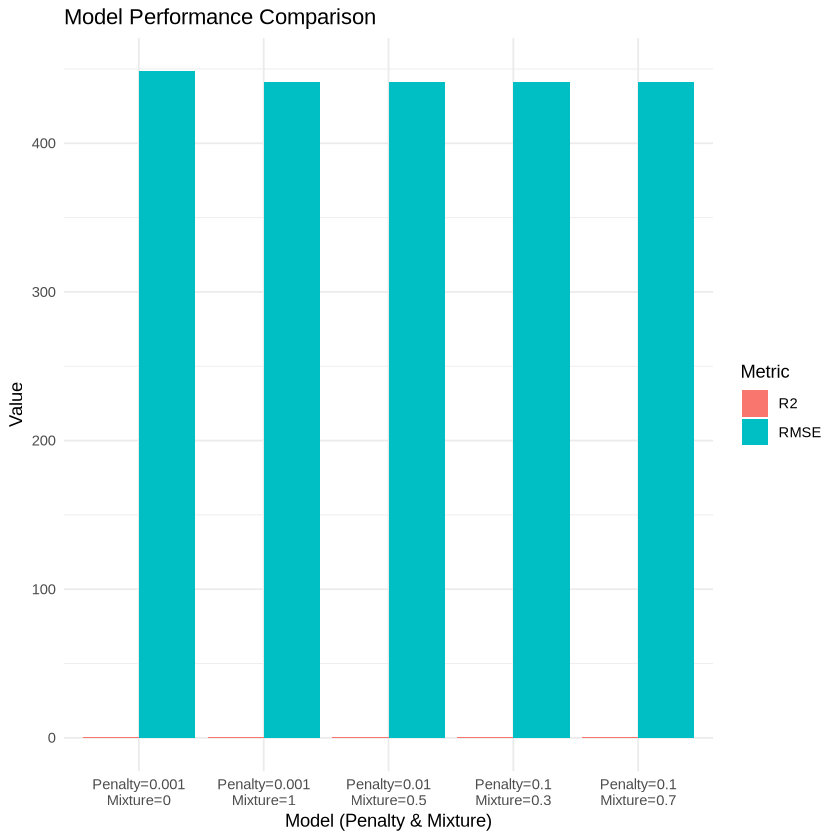

In [45]:
library(dplyr)
library(tidyr)
library(ggplot2)

# ✅ Find best model
best_model <- results %>%
  arrange(RMSE, desc(R2)) %>%
  slice(1)

# ✅ Check performance requirements
if(best_model$RMSE < 330 & best_model$R2 > 0.72) {
  cat("✅ Best model meets performance requirements!\n")
} else {
  cat("❌ Best model does NOT meet performance requirements.\n")
}

# ✅ Prepare data for grouped bar chart
results_long <- results %>%
  pivot_longer(cols = c(RMSE, R2), names_to = "Metric", values_to = "Value")

# ✅ Plot grouped bar chart
ggplot(results_long, aes(x = paste0("Penalty=", Penalty, "\nMixture=", Mixture),
                         y = Value, fill = Metric)) +
  geom_bar(stat = "identity", position = "dodge") +
  labs(title = "Model Performance Comparison",
       x = "Model (Penalty & Mixture)", y = "Value") +
  theme_minimal()



_TODO:_ Create a Q-Q plot by plotting the distribution difference between the predictions generated by your best model and the true values on the test dataset.


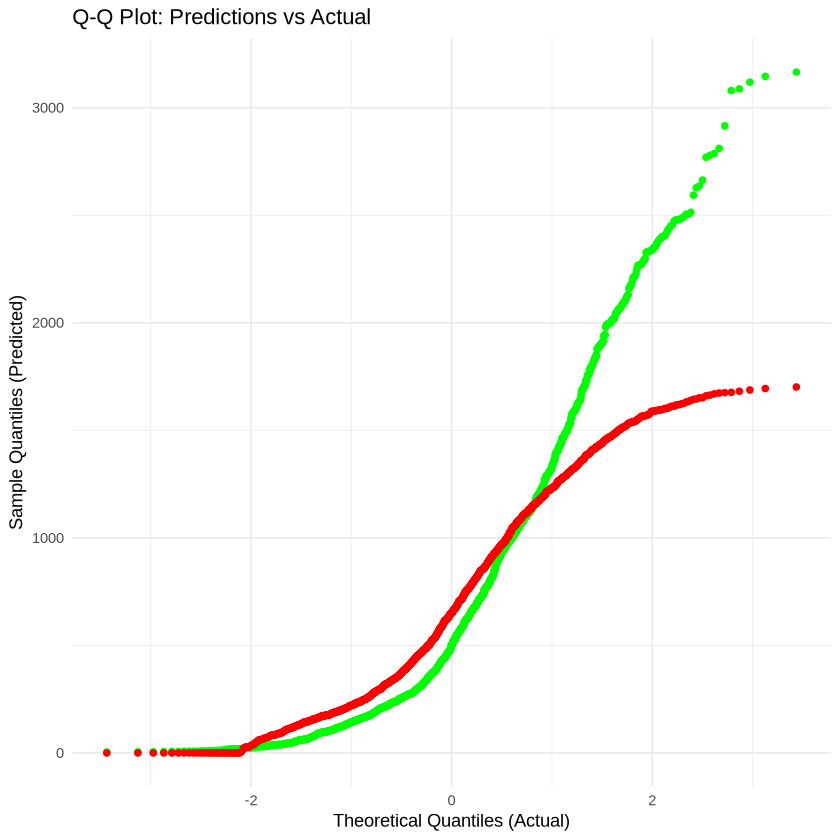

In [48]:
library(ggplot2)

# Refit the best model using its penalty and mixture values
best_model_fit <- linear_reg(
  penalty = best_model$Penalty,
  mixture = best_model$Mixture
) %>%
  set_engine("glmnet") %>%
  set_mode("regression") %>%
  fit(formula, data = train_data)

# Predictions from the best model
best_preds <- pmax(predict(best_model_fit, new_data = test_data)$.pred, 0)

# Build Q-Q plot comparing distributions
qq_df <- data.frame(
  truth = test_data$RENTED_BIKE_COUNT,
  prediction = best_preds
)

ggplot(qq_df) +
  stat_qq(aes(sample = truth), color = "green") +
  stat_qq(aes(sample = prediction), color = "red") +
  labs(title = "Q-Q Plot: Predictions vs Actual",
       x = "Theoretical Quantiles (Actual)",
       y = "Sample Quantiles (Predicted)") +
  theme_minimal()


One example of such Q-Q plot may look like this:


<a href="https://cognitiveclass.ai/">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-RP0321EN-SkillsNetwork/labs/module_4/images/example_qq_plot.png" width="600" align="center">
</a>


# More model improvment methods beyond this course


In addition to the methods mentioned in this lab and previous data analysis courses, you could also explore to try the following methods yourself to see if they could improve model performance:
 - Remove potential redundant variables. If two variables have extremly high correlated, it is possible that they are redundant and could be removed from the model to improve the performance.
 - Remove some outliers. Linear regression models are very sensitive to outliers, you could try to remove some outliers to see if it would improve performance
 - Apply logarithm transformation. In case variable distributions are not normal distribution such as log-normal distribution, you could apply logaritm transformation on the variable to make them more look like normal distribution. In addition, logarithm transformation helps capture the non-linear relationships.
 
If you have time, you could research and try more methods by searching related research papers/articles, discussion forums, etc. If you know how to use other machine learning models with `Tidymodels` such as Neural Networks, Tree models, or Boosting models, you can also try and compare them with the linear regression models.


# Next Steps:


Great! You have improved your baseline model using polynomial terms, interaction terms, and regularizations, and have found your best model.

Now it's time to build an interactive dashboard to provide more interactive user-interactions.


## Authors

<a href="https://www.linkedin.com/in/yan-luo-96288783/" target="_blank">Yan Luo</a>


### Other Contributors

Jeff Grossman


## Change Log

| Date (YYYY-MM-DD) | Version | Changed By | Change Description           |
| ----------------- | ------- | ---------- | ---------------------------- |
| 2021-04-08        | 1.0     | Yan        | Initial version created      |
|                   |         |            |                              |
|                   |         |            |                              |

## <h3 align="center"> © IBM Corporation. All rights reserved. <h3/>
